# Effect of Different n Values on Stability and Eigenvalues

See how different Hill coefficients (n values) for each neuron type (r, g, b, y) affect network stability

In [4]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from itertools import product

# Set random seed for reproducibility
key = jax.random.PRNGKey(42)
np.random.seed(42)

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal


## Modified Functions with Different n Values

We modify the Naka-Rushton function and circuit functions to accept different n values for each neuron type: n_r, n_g, n_b, n_y.


In [6]:
# Naka-Rushton function
def nr(x, n=4):
    """Naka-Rushton activation function"""
    return x**n / (x**n + 1)

# Unpack parameters
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r=4, n_b=4, n_g=4):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)
    
    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)
    
    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)
    
    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r=4, n_b=4, n_g=4):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)
    
    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)
    
    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r=4, n_b=4, n_g=4, n_y=4):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    
    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)
    
    return r, g, b, y


## Dynamics Function and Stability Analysis

We define the dynamics function F(s) and compute stability with different n values.


In [7]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=4, n_b=4, n_g=4, n_y=4):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r=4, n_b=4, n_g=4, n_y=4):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_g, n_y)
    
    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=4, n_b=4, n_g=4, n_y=4):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [8]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_1000_samples_n_4_target_0.5.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")




Loaded theta_opt with shape: (1000, 28)
Number of samples: 1000
Number of parameters per sample: 28


In [9]:
def check_single_theta_np(theta, x, m):
    """Check single theta sample - using numpy for compatibility"""
    r, g, b, y = mitral_output(theta, x, m)
    # Convert to numpy arrays
    r = np.array(r)
    g = np.array(g)
    b = np.array(b)
    y = np.array(y)

    # Check if all elements are in [0.4, 0.6]
    r_ok = (r >= 0.4).all() and (r <= 0.6).all()
    g_ok = (g >= 0.4).all() and (g <= 0.6).all()
    b_ok = (b >= 0.4).all() and (b <= 0.6).all()
    y_ok = (y >= 0.4).all() and (y <= 0.6).all()

    return r_ok and g_ok and b_ok and y_ok

# Process samples
n_samples = theta_opt.shape[0]
valid_mask = np.zeros(n_samples, dtype=bool)

for i in range(n_samples):
    theta_star = jnp.array(theta_opt[i, :])
    valid_mask[i] = check_single_theta_np(theta_star, x, m)

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{n_samples} samples...")

theta_opt = theta_opt[valid_mask]

print(f"Number of valid theta_opt: {theta_opt.shape[0]} out of {n_samples}")

KeyboardInterrupt: 

In [55]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Using 982 samples for analysis


## Different n Value Combinations

We'll test different combinations of n values for each neuron type and analyze their effects on stability and eigenvalues.


no of action potentials vs injected current
- mitral (55, 400 pA)
- ETCs (40, 195 pA)
- blue (5, 70 pA)
- green (12, 100 pA)

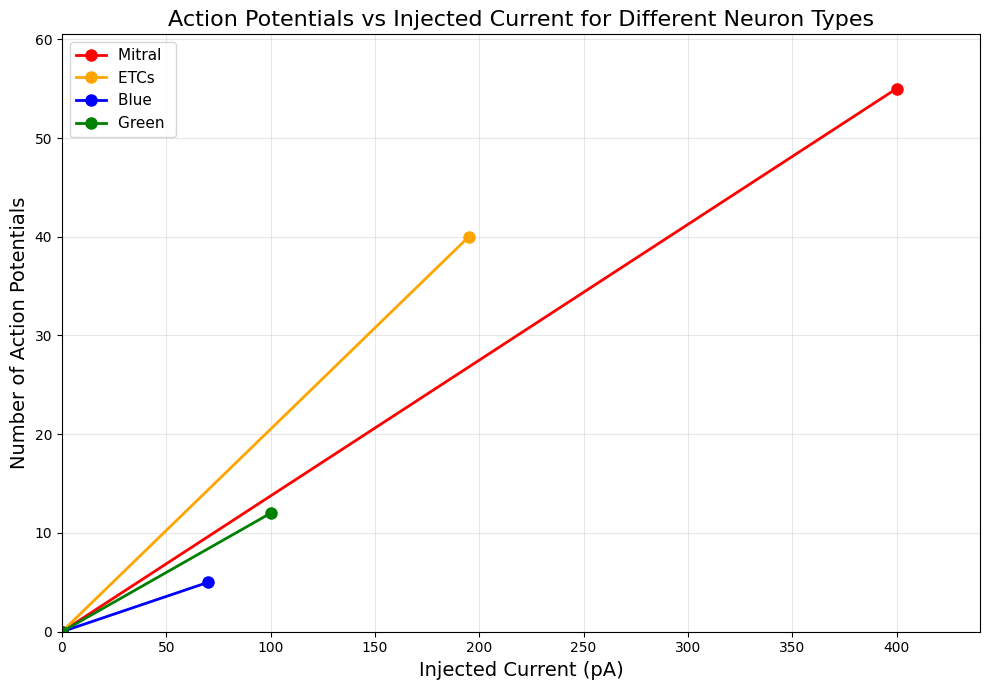

In [52]:

# Plot action potentials vs injected current for each neuron type
# All lines pass through origin and the given point

# Define data points for each neuron type
neuron_data = {
    'Mitral': {'ap': 55, 'current': 400, 'color': 'red'},
    'ETCs': {'ap': 40, 'current': 195, 'color': 'orange'},
    'Blue': {'ap': 5, 'current': 70, 'color': 'blue'},
    'Green': {'ap': 12, 'current': 100, 'color': 'green'}
}

# Create figure
fig, ax = plt.subplots(figsize=(10, 7))

# Plot each neuron type
for neuron_name, data in neuron_data.items():
    ap = data['ap']
    current = data['current']
    color = data['color']
    
    # Create line from origin (0, 0) to the given point
    x_line = np.array([0, current])
    y_line = np.array([0, ap])
    
    # Plot the line
    ax.plot(x_line, y_line, color=color, linewidth=2, 
            label=f'{neuron_name} ', marker='o', markersize=8)

ax.set_xlabel('Injected Current (pA)', fontsize=14)
ax.set_ylabel('Number of Action Potentials', fontsize=14)
ax.set_title('Action Potentials vs Injected Current for Different Neuron Types', fontsize=16)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11, loc='best')
ax.set_xlim(0, max([d['current'] for d in neuron_data.values()]) * 1.1)
ax.set_ylim(0, max([d['ap'] for d in neuron_data.values()]) * 1.1)

plt.tight_layout()
plt.show()



In [12]:
# Define n values to test

# Test different combinations - all values must come from n_values_to_test
n_combinations = [
    # Baseline: all same (lowest value)
    {'n_r': 4, 'n_b': 4, 'n_g': 4, 'n_y': 4, 'name': 'Baseline (all n=4)'},
    
    {'n_r': 12, 'n_b': 4, 'n_g': 7, 'n_y': 8, 'name': 'r=12, b=4, g=7, y=8'},
    {'n_r': 16, 'n_b': 2, 'n_g': 6, 'n_y': 8, 'name': 'r=16, b=2, g=6, y=8'},
]

print(f"Testing {len(n_combinations)} different n value combinations")
for i, combo in enumerate(n_combinations):
    print(f"{i+1}. {combo['name']}: n_r={combo['n_r']}, n_b={combo['n_b']}, n_g={combo['n_g']}, n_y={combo['n_y']}")


Testing 3 different n value combinations
1. Baseline (all n=4): n_r=4, n_b=4, n_g=4, n_y=4
2. r=12, b=4, g=7, y=8: n_r=12, n_b=4, n_g=7, n_y=8
3. r=16, b=2, g=6, y=8: n_r=16, n_b=2, n_g=6, n_y=8


## Stability Analysis for Different n Values

For each combination of n values, we compute:
1. Stability (whether all eigenvalues have negative real parts)
2. Real parts of eigenvalues



In [56]:
# Analyze stability for each n combination

stability_results_all = {}

for combo in n_combinations:
    n_r = combo['n_r']
    n_b = combo['n_b']
    n_g = combo['n_g']
    n_y = combo['n_y']
    name = combo['name']
    
    print(f"\n{'='*70}")
    print(f"Analyzing: {name}")
    print(f"{'='*70}")
    
    stability_results = []
    max_real_parts = []
    min_real_parts = []
    all_eigenvalues = []
    
    for i in range(n_samples_to_analyze):
        theta_star = theta_subset[i, :]
        
        # Get fixed point outputs with new n values
        try:
            r_star, g_star, b_star, y_star = mitral_output(theta_star, x, m, n_r, n_b, n_g, n_y)
            
            # Construct state vector s* = [r, g, y]
            s_star = jnp.concatenate([r_star, g_star, y_star])
            
            # Verify it's a fixed point
            s_prime = F(s_star, theta_star, x, m, n_r, n_b, n_g, n_y)
            s_error = jnp.linalg.norm(s_prime - s_star)
            
            if s_error > 1e-3:
                print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")
            
            # Compute stability
            result = compute_stability(F, s_star, theta_star, x, m, tau=1.0, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
            stability_results.append(result)
            
            max_real_parts.append(np.max(result['real_parts']))
            min_real_parts.append(np.min(result['real_parts']))
            all_eigenvalues.append(result['eigenvalues'])
            
        except Exception as e:
            print(f"  Sample {i+1}: Error - {e}")
            continue
    
    # Store results
    stability_results_all[name] = {
        'results': stability_results,
        'max_real_parts': np.array(max_real_parts),
        'min_real_parts': np.array(min_real_parts),
        'all_eigenvalues': all_eigenvalues,
        'n_r': n_r,
        'n_b': n_b,
        'n_g': n_g,
        'n_y': n_y,
        'stable_count': sum(1 for r in stability_results if r['is_stable']),
        'total_count': len(stability_results)
    }
    
    stable_pct = 100 * stability_results_all[name]['stable_count'] / stability_results_all[name]['total_count']
    print(f"\nStability: {stability_results_all[name]['stable_count']}/{stability_results_all[name]['total_count']} stable ({stable_pct:.1f}%)")
    print(f"Max real part range: [{np.min(max_real_parts):.4f}, {np.max(max_real_parts):.4f}]")
    print(f"Min real part range: [{np.min(min_real_parts):.4f}, {np.max(min_real_parts):.4f}]")



Analyzing: Baseline (all n=4)

Stability: 982/982 stable (100.0%)
Max real part range: [-1.0000, -0.1676]
Min real part range: [-1.8324, -1.0000]

Analyzing: r=12, b=4, g=7, y=8
  Sample 19: Warning - fixed point error = 1.07e-02
  Sample 54: Warning - fixed point error = 8.82e-03
  Sample 63: Warning - fixed point error = 6.34e-03
  Sample 79: Warning - fixed point error = 3.15e-03
  Sample 93: Warning - fixed point error = 2.08e-03
  Sample 104: Warning - fixed point error = 2.30e-02
  Sample 123: Warning - fixed point error = 2.12e-02
  Sample 138: Warning - fixed point error = 5.98e-03
  Sample 150: Warning - fixed point error = 3.69e-03
  Sample 154: Warning - fixed point error = 2.16e-02
  Sample 184: Warning - fixed point error = 3.18e-03
  Sample 192: Warning - fixed point error = 3.49e-03
  Sample 199: Warning - fixed point error = 1.88e-03
  Sample 208: Warning - fixed point error = 4.23e-03
  Sample 227: Warning - fixed point error = 2.37e-03
  Sample 277: Warning - fixed p

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


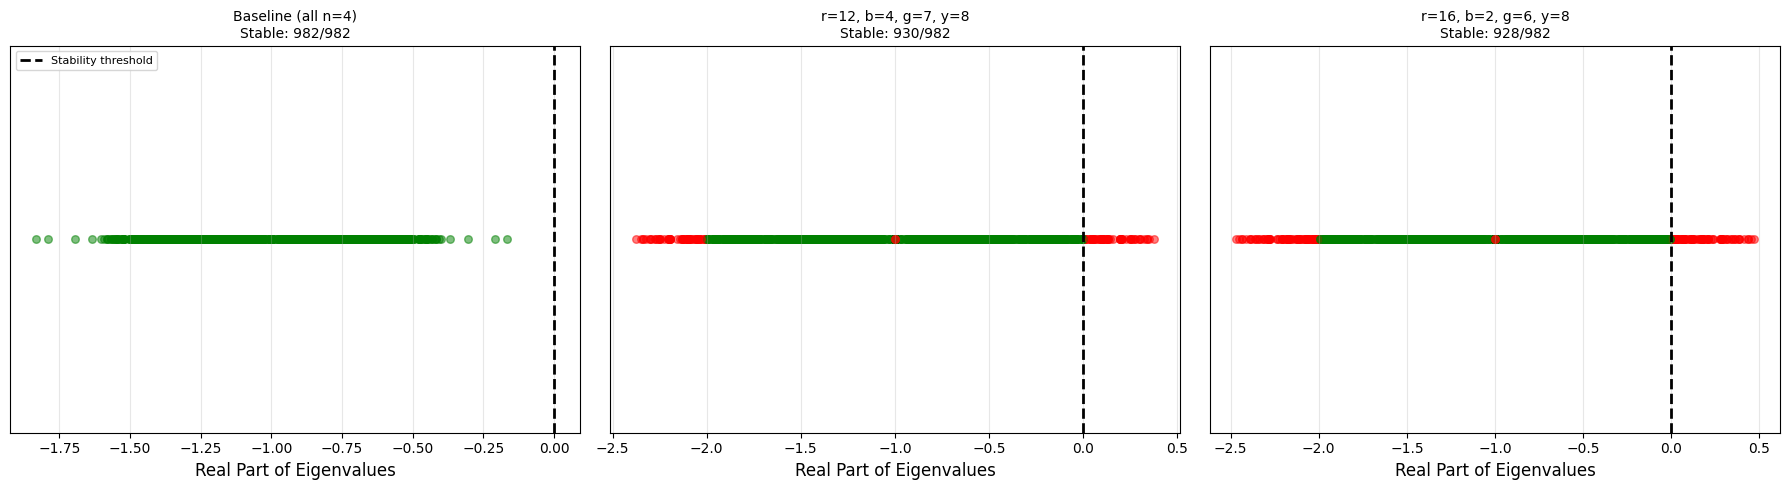

In [57]:
# Plot stability results
# Dynamically determine grid size based on number of combinations
n_combos = len(stability_results_all)
n_cols = 3
n_rows = (n_combos + n_cols - 1) // n_cols  # Ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
if n_combos == 1:
    axes = [axes]  # Make it iterable
else:
    axes = axes.flatten()

for idx, (name, data) in enumerate(stability_results_all.items()):
    ax = axes[idx]
    
    # Plot eigenvalues for all samples - only real parts
    for i, result in enumerate(data['results']):
        real_parts = result['real_parts']
        
        # Color by stability
        color = 'green' if result['is_stable'] else 'red'
        # Plot real parts as points along x-axis (y=0 for all)
        ax.scatter(real_parts, np.zeros_like(real_parts), alpha=0.5, s=30, color=color)
    
    ax.axvline(x=0, color='black', linestyle='--', linewidth=2, label='Stability threshold')
    ax.set_xlabel('Real Part of Eigenvalues', fontsize=12)
    ax.set_ylabel('', fontsize=12)
    ax.set_title(f"{name}\nStable: {data['stable_count']}/{data['total_count']}", fontsize=10)
    ax.grid(True, alpha=0.3, axis='x')
    ax.set_ylim(-0.1, 0.1)  # Small range around y=0
    ax.set_yticks([])  # Remove y-axis ticks
    if idx == 0:  # Only show legend on first plot
        ax.legend(fontsize=8)

# Hide unused subplots
for idx in range(n_combos, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig('Figures/stability_different_n_values.eps', format='eps', dpi=300)
plt.show()


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


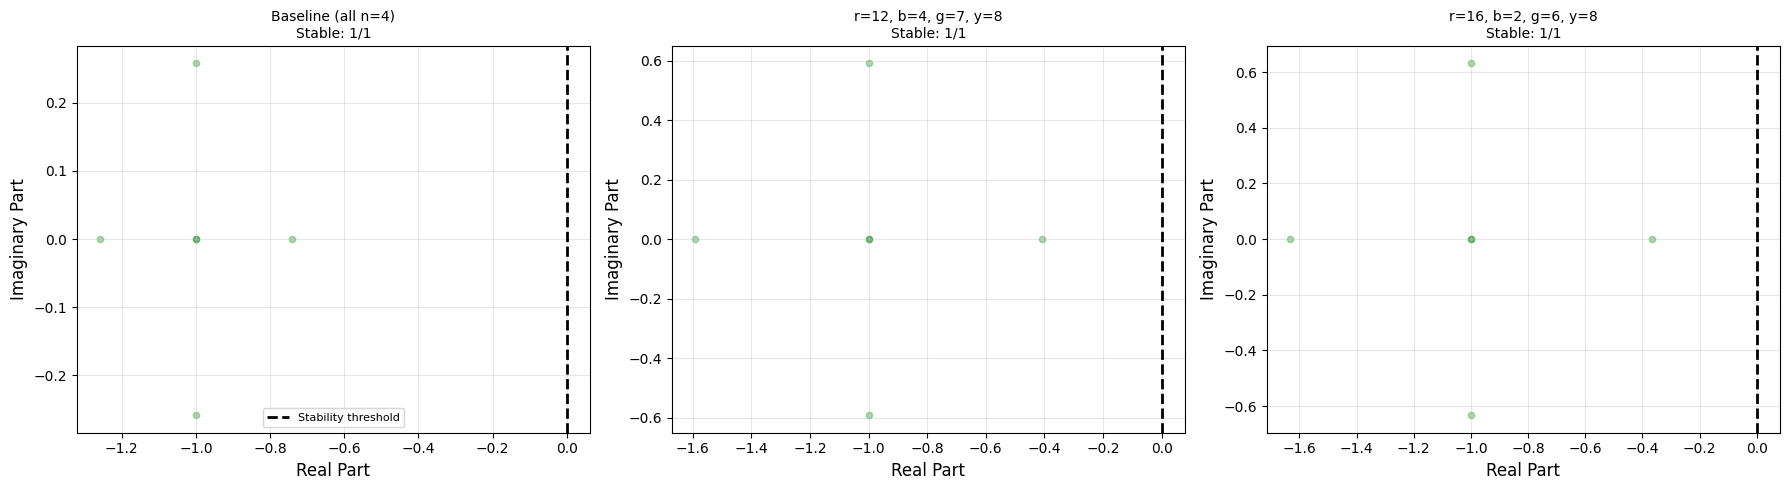

In [26]:
# Plot stability results (complex plane - real vs imaginary parts)
# Dynamically determine grid size based on number of combinations
n_combos = len(stability_results_all)
n_cols = 3
n_rows = (n_combos + n_cols - 1) // n_cols  # Ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
if n_combos == 1:
    axes = [axes]  # Make it iterable
else:
    axes = axes.flatten()

for idx, (name, data) in enumerate(stability_results_all.items()):
    ax = axes[idx]
    
    # Plot eigenvalues for all samples
    for i, result in enumerate(data['results']):
        real_parts = result['real_parts']
        imag_parts = result['imag_parts']
        
        # Color by stability
        color = 'green' if result['is_stable'] else 'red'
        ax.scatter(real_parts, imag_parts, alpha=0.3, s=20, color=color)
    
    ax.axvline(x=0, color='black', linestyle='--', linewidth=2, label='Stability threshold')
    ax.set_xlabel('Real Part', fontsize=12)
    ax.set_ylabel('Imaginary Part', fontsize=12)
    ax.set_title(f"{name}\nStable: {data['stable_count']}/{data['total_count']}", fontsize=10)
    ax.grid(True, alpha=0.3)
    if idx == 0:  # Only show legend on first plot
        ax.legend(fontsize=8)

# Hide unused subplots
for idx in range(n_combos, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig('Figures/stability_different_n_values.eps', format='eps', dpi=300)
plt.show()

Try just a few to see how star shape forms


In [15]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = 1
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Using 1 samples for analysis


In [17]:
# Analyze stability for each n combination

stability_results_all = {}

for combo in n_combinations:
    n_r = combo['n_r']
    n_b = combo['n_b']
    n_g = combo['n_g']
    n_y = combo['n_y']
    name = combo['name']
    
    print(f"\n{'='*70}")
    print(f"Analyzing: {name}")
    print(f"{'='*70}")
    
    stability_results = []
    max_real_parts = []
    min_real_parts = []
    all_eigenvalues = []
    
    for i in range(n_samples_to_analyze):
        theta_star = theta_subset[i, :]
        
        # Get fixed point outputs with new n values
        try:
            r_star, g_star, b_star, y_star = mitral_output(theta_star, x, m, n_r, n_b, n_g, n_y)
            
            # Construct state vector s* = [r, g, y]
            s_star = jnp.concatenate([r_star, g_star, y_star])
            
            # Verify it's a fixed point
            s_prime = F(s_star, theta_star, x, m, n_r, n_b, n_g, n_y)
            s_error = jnp.linalg.norm(s_prime - s_star)
            
            if s_error > 1e-3:
                print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")
            
            # Compute stability
            result = compute_stability(F, s_star, theta_star, x, m, tau=1.0, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
            stability_results.append(result)
            
            max_real_parts.append(np.max(result['real_parts']))
            min_real_parts.append(np.min(result['real_parts']))
            all_eigenvalues.append(result['eigenvalues'])
            
        except Exception as e:
            print(f"  Sample {i+1}: Error - {e}")
            continue
    
    # Store results
    stability_results_all[name] = {
        'results': stability_results,
        'max_real_parts': np.array(max_real_parts),
        'min_real_parts': np.array(min_real_parts),
        'all_eigenvalues': all_eigenvalues,
        'n_r': n_r,
        'n_b': n_b,
        'n_g': n_g,
        'n_y': n_y,
        'stable_count': sum(1 for r in stability_results if r['is_stable']),
        'total_count': len(stability_results)
    }
    
    stable_pct = 100 * stability_results_all[name]['stable_count'] / stability_results_all[name]['total_count']
    print(f"\nStability: {stability_results_all[name]['stable_count']}/{stability_results_all[name]['total_count']} stable ({stable_pct:.1f}%)")
    print(f"Max real part range: [{np.min(max_real_parts):.4f}, {np.max(max_real_parts):.4f}]")
    print(f"Min real part range: [{np.min(min_real_parts):.4f}, {np.max(min_real_parts):.4f}]")



Analyzing: Baseline (all n=4)

Stability: 1/1 stable (100.0%)
Max real part range: [-0.7418, -0.7418]
Min real part range: [-1.2582, -1.2582]

Analyzing: r=12, b=4, g=7, y=8

Stability: 1/1 stable (100.0%)
Max real part range: [-0.4085, -0.4085]
Min real part range: [-1.5915, -1.5915]

Analyzing: r=16, b=2, g=6, y=8

Stability: 1/1 stable (100.0%)
Max real part range: [-0.3676, -0.3676]
Min real part range: [-1.6324, -1.6324]


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


[-1.         -1.         -1.2581564  -0.9999999  -0.9999999  -0.74184394]
[-1.        -1.        -1.5915116 -1.0000005 -1.0000005 -0.4084892]
[-1.         -1.         -1.6323527  -0.9999999  -0.9999999  -0.36764812]


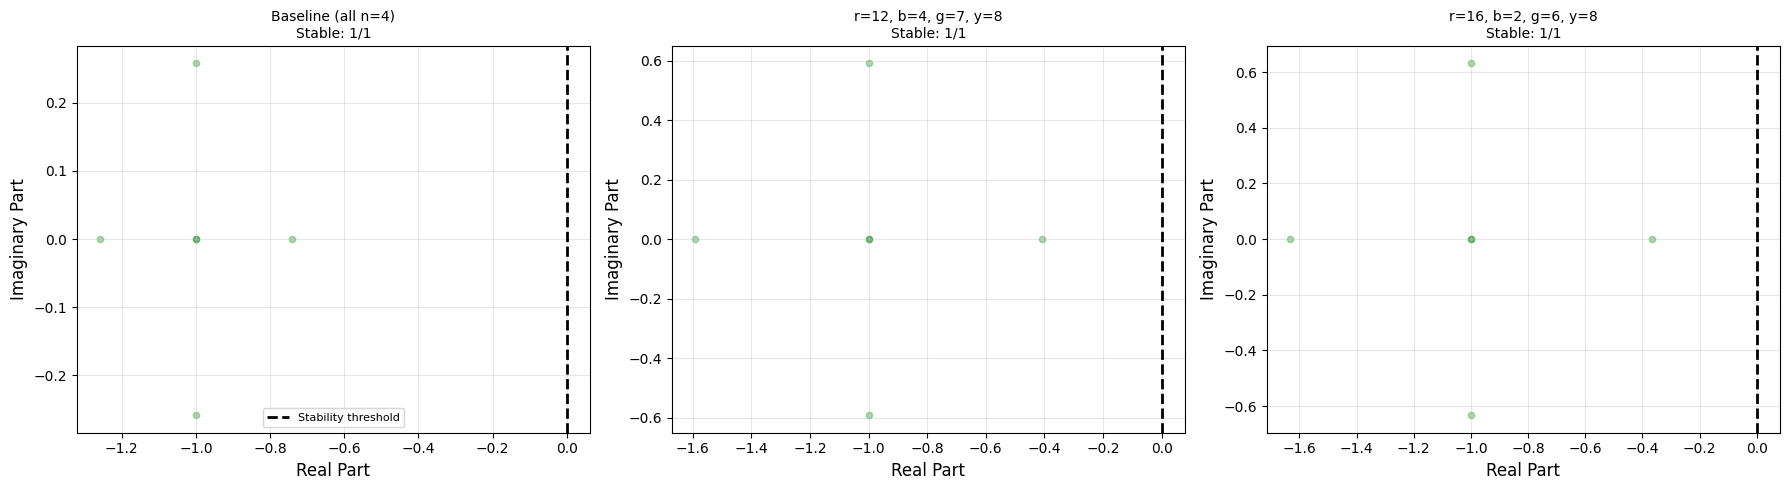

In [21]:
# Plot stability results (complex plane - real vs imaginary parts)
# Dynamically determine grid size based on number of combinations
n_combos = len(stability_results_all)
n_cols = 3
n_rows = (n_combos + n_cols - 1) // n_cols  # Ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
if n_combos == 1:
    axes = [axes]  # Make it iterable
else:
    axes = axes.flatten()

for idx, (name, data) in enumerate(stability_results_all.items()):
    ax = axes[idx]
    
    # Plot eigenvalues for all samples
    for i, result in enumerate(data['results']):
        real_parts = result['real_parts']
        imag_parts = result['imag_parts']
        print(real_parts)
        
        # Color by stability
        color = 'green' if result['is_stable'] else 'red'
        ax.scatter(real_parts, imag_parts, alpha=0.3, s=20, color=color)
    
    ax.axvline(x=0, color='black', linestyle='--', linewidth=2, label='Stability threshold')
    ax.set_xlabel('Real Part', fontsize=12)
    ax.set_ylabel('Imaginary Part', fontsize=12)
    ax.set_title(f"{name}\nStable: {data['stable_count']}/{data['total_count']}", fontsize=10)
    ax.grid(True, alpha=0.3)
    if idx == 0:  # Only show legend on first plot
        ax.legend(fontsize=8)

# Hide unused subplots
for idx in range(n_combos, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig('Figures/stability_different_n_values.eps', format='eps', dpi=300)
plt.show()